# Etapa 2 — Regressões, gradiente descendente, Ridge e logística

Contagens passam por log1p; o delta anterior usa transformação assinada. Hiperparâmetros não são escolhidos olhando o teste.

**Fonte:** BancoVDE 2026.xlsx / MJSP. **Semente:** 42.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _find_root():
    """Localiza a raiz do projeto (pasta com scripts/utils.py e data/) a partir do diretório atual."""
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "scripts" / "utils.py").exists() and (base / "data").exists():
            return base
    for pattern in ("*/scripts/utils.py", "*/*/scripts/utils.py"):   # ex.: Colab em /content
        for hit in sorted(here.glob(pattern)):
            if (hit.parent.parent / "data").exists():
                return hit.parent.parent
    raise FileNotFoundError(
        "Raiz do projeto não encontrada: abra o notebook com o diretório atual "
        "dentro da pasta FIA_P3_SegurancaPublica_Equipe5."
    )

ROOT = _find_root()

sys.path.insert(0, str(ROOT / "scripts"))
sys.modules.pop("utils", None)

from utils import (
    panel,
    training_split,
    prepare_splits,
    temporal_split,
    write_metrics
)

np.random.seed(42)
(ROOT / "outputs").mkdir(exist_ok=True)

print("Configuração da etapa 2 concluída!")

Configuração da etapa 2 concluída!


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LinearRegression, LogisticRegression
from sklearn.metrics import r2_score, accuracy_score
from utils import regression_features, linear_gd, logistic_gd

p, tr, te, _ = training_split()

Xtr = regression_features(tr)
Xte = regression_features(te)

ytr = np.log1p(tr.contagem.to_numpy(float))
yte = np.log1p(te.contagem.to_numpy(float))

sc = StandardScaler()

A = sc.fit_transform(Xtr)
B = sc.transform(Xte)

print("Atributos:")
print(" log1p(lag1)")
print(" log1p(media_previa)")
print(" sign(delta) * log1p(abs(delta))")

Atributos:
 log1p(lag1)
 log1p(media_previa)
 sign(delta) * log1p(abs(delta))


## Regressão simples por expressão fechada
A reta minimiza o erro quadrático com $b_1=\mathrm{Cov}(x,y)/\mathrm{Var}(x)$ e $b_0=\bar y-b_1\bar x$. O coeficiente $R^2$ é medido em observações não usadas no ajuste.

In [3]:
x = Xtr[:, 0]

slope = (
    ((x - x.mean()) * (ytr - ytr.mean())).sum()
    / ((x - x.mean()) ** 2).sum()
)

intercept = float(ytr.mean() - slope * x.mean())

uni_pred = intercept + slope * Xte[:, 0]

uni_r2 = r2_score(yte, uni_pred)

print("Regressão linear univariada")
print("Intercepto (b0):", intercept)
print("Coeficiente angular (b1):", slope)
print("R² no teste:", uni_r2)

Regressão linear univariada
Intercepto (b0): 0.06521203856718838
Coeficiente angular (b1): 0.9757146629225704
R² no teste: 0.9577783719668116


## Gradiente descendente do zero e comparação com mínimos quadrados
A escala logarítmica aplicada aos três atributos facilita o ajuste numérico porque comprime variações de ordens de grandeza entre indicadores estaduais. Um R² elevado não é prova de previsão de oscilações abruptas ou de causalidade.

R² Gradiente Descendente: 0.9661454797392388
R² Scikit-learn: 0.9659258184325824


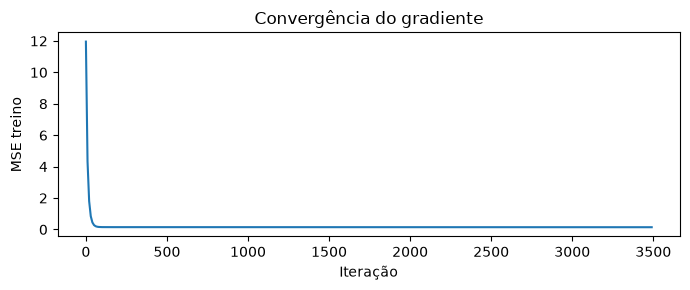

In [4]:
w, h = linear_gd(A, ytr)

pred = np.c_[np.ones(len(B)), B] @ w
gd_r2 = r2_score(yte, pred)

lin = LinearRegression()
lin.fit(A, ytr)

lin_r2 = lin.score(B, yte)

print("R² Gradiente Descendente:", gd_r2)
print("R² Scikit-learn:", lin_r2)

plt.figure(figsize=(7, 3))

plt.plot(
    np.arange(len(h)) * 10,
    h
)

plt.xlabel("Iteração")
plt.ylabel("MSE treino")
plt.title("Convergência do gradiente")

plt.tight_layout()

plt.savefig(
    ROOT / "outputs" / "gradiente.png",
    dpi=160
)

plt.show()

## Regularização Ridge (L2)
O $\lambda$ é selecionado por validação cruzada **dentro do treino**; a curva de coeficientes é examinada separadamente. Não se maximiza desempenho em teste para escolher $\lambda$.

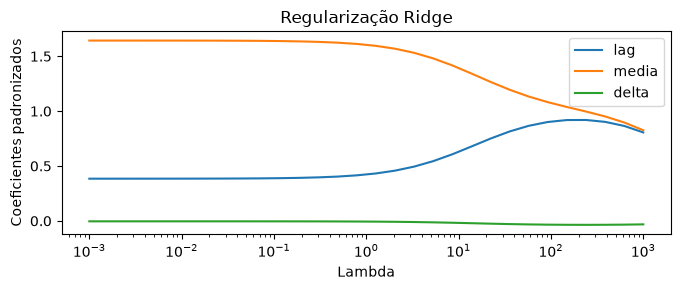

Ridge lambda selecionado no treino: 0.11721022975334805
R² no teste: 0.9659341223842512


In [5]:
from sklearn.linear_model import Ridge, RidgeCV

alpha_grid = np.logspace(-3, 3, 30)

ridge = RidgeCV(
    alphas=alpha_grid,
    cv=5
)

ridge.fit(A, ytr)

coef = np.array([
    Ridge(alpha=alpha).fit(A, ytr).coef_
    for alpha in alpha_grid
])

plt.figure(figsize=(7, 3))

for j, name in enumerate(['lag', 'media', 'delta']):
    plt.semilogx(
        alpha_grid,
        coef[:, j],
        label=name
    )

plt.xlabel("Lambda")
plt.ylabel("Coeficientes padronizados")
plt.title("Regularização Ridge")
plt.legend()
plt.tight_layout()

plt.savefig(
    ROOT / "outputs" / "ridge.png",
    dpi=160
)

plt.show()

ridge_r2 = ridge.score(B, yte)

print("Ridge lambda selecionado no treino:", ridge.alpha_)
print("R² no teste:", ridge_r2)

## Regressão logística do zero
A sigmoide e o gradiente de entropia cruzada são implementados sem a biblioteca; a comparação usa o mesmo conjunto e o alvo da Etapa 1.

In [6]:
ztr = tr.alto.to_numpy(int)
zte = te.alto.to_numpy(int)

wl = logistic_gd(A, ztr)

sig = lambda t: 1 / (1 + np.exp(-np.clip(t, -35, 35)))

loggd = accuracy_score(
    zte,
    (sig(np.c_[np.ones(len(B)), B] @ wl) >= 0.5).astype(int)
)

logsk = (
    LogisticRegression(max_iter=3000)
    .fit(A, ztr)
    .score(B, zte)
)

pt, tt, _ = temporal_split(p)

sp = StandardScaler()

AT = sp.fit_transform(regression_features(pt))
BT = sp.transform(regression_features(tt))

mt = LinearRegression().fit(
    AT,
    np.log1p(pt.contagem)
)

time_r2 = mt.score(
    BT,
    np.log1p(tt.contagem)
)

print("Regressão logística GD:", loggd)
print("Regressão logística Scikit-learn:", logsk)
print("R² temporal:", time_r2)

metrics = {
    'univariate_r2_test': uni_r2,
    'gd_r2_test': gd_r2,
    'linear_sklearn_r2_test': lin_r2,
    'ridge_r2_test': ridge_r2,
    'ridge_lambda_cv': float(ridge.alpha_),
    'logistic_gd_accuracy': loggd,
    'logistic_sklearn_accuracy': logsk,
    'temporal_r2': time_r2
}

write_metrics('etapa2.json', metrics)

Regressão logística GD: 0.8494208494208494
Regressão logística Scikit-learn: 0.861003861003861
R² temporal: 0.9717535449140798


PosixPath('FIA_P3_SegurancaPublica_Equipe5/outputs/etapa2.json')

## Regressão de taxa mensal por 100 mil como análise complementar
Nesta análise descritiva, o alvo $\log(1+\mathrm{taxa}_{100mil})$ tem unidade e escala homogêneas entre estados **para um mesmo indicador**. Os lags também são normalizados pela estimativa populacional do IBGE de 2026.

In [7]:
import json

def rate_features(df):
    d = 100000 / df.populacao_2026.to_numpy(float)

    lag = df.lag1.to_numpy(float) * d
    mean = df.media_previa.to_numpy(float) * d
    delta = df.delta_previo.to_numpy(float) * d

    return np.column_stack([
        np.log1p(lag),
        np.log1p(mean),
        np.sign(delta) * np.log1p(np.abs(delta))
    ])


rate_sc = StandardScaler()

ra = rate_sc.fit_transform(rate_features(tr))
rb = rate_sc.transform(rate_features(te))

rate_reg = LinearRegression().fit(
    ra,
    np.log1p(tr.taxa_por100mil)
)

rate_r2 = rate_reg.score(
    rb,
    np.log1p(te.taxa_por100mil)
)

print("R² da taxa mensal por 100 mil habitantes:", rate_r2)

mm = json.loads(
    (ROOT / "outputs" / "etapa2.json").read_text()
)

mm["rate_r2_test"] = rate_r2

write_metrics("etapa2.json", mm)

R² da taxa mensal por 100 mil habitantes: 0.9678491180157436


PosixPath('FIA_P3_SegurancaPublica_Equipe5/outputs/etapa2.json')